# Part 1. Hypothesis testing in Python and preparing an analytical note

You preprocessed the data in SQL, and now it is ready for hypothesis testing in Python. Load the data of users from Moscow and Saint Petersburg with their total hours of activity from the file yandex_knigi_data.csv. If you work locally, you can download the file from the link.

Check the user identifiers for duplicates. Compare the sizes of the groups, their statistics and distributions.

Let us recall the hypothesis: users from Saint Petersburg spend on average more time reading and listening to books in the app than users from Moscow. Try to prove this statistically using a one-sided hypothesis test with two samples:

Null hypothesis $H_0: \mu_{\text{SPb}} \leq \mu_{\text{Moscow}}$ <br> The average activity time of users in Saint Petersburg is not greater than in Moscow.

Alternative hypothesis $H_1: \mu_{\text{SPb}} > \mu_{\text{Moscow}}$ <br> The average activity time of users in Saint Petersburg is greater, and this difference is statistically significant.

Based on the results of the data analysis, prepare an analytical note that describes:

The chosen type of t-test and the level of statistical significance.

The test result, or p-value.

A conclusion based on the obtained p-value, that is, an interpretation of the results.

One or two possible reasons that explain the obtained results.

## Reading Activity: Moscow vs. Saint Petersburg

- Author: Fedor Vo
- Date: 23.11

## Project goals and objectives

The Yandex Books team studied the data obtained from the LTV analysis and put forward a hypothesis. It is that users who bring a higher LTV are more loyal, and therefore spend on average more time reading and listening to books in the app.

The team proposes to compare users from Saint Petersburg and Moscow, because the average LTV calculations showed that this metric is higher for Saint Petersburg residents. Thus, the hypothesis is: users from Saint Petersburg spend on average more time reading and listening to books in the app compared to users from Moscow. In this and the following lessons of the project, you will need to test this hypothesis.

## Data description

The tables of this project contain data on reading and listening to content in the Yandex Books service, including information about users, platforms, time, session duration and content types. The data covers the period from 1 September to 11 December 2024.

## Project contents

- Bring the data to the form: city, ID and reading time (listening also counts)
- Test the hypothesis that users from Saint Petersburg spend more time

## 1. Loading the data and getting to know it

Load the data of users from Moscow and Saint Petersburg with their activity (total hours of reading and listening) from the file `/datasets/yandex_knigi_data.csv`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np

# Import data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns 

from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest

In [2]:
df = pd.read_csv('/datasets/yandex_knigi_data.csv', index_col=0)
df.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [3]:
df.shape[0]

8784

In [4]:
df.duplicated().sum()

0

In [5]:
df.duplicated(['city', 'puid']).sum()

0

In [6]:
df[df.duplicated('puid', keep=False)].sort_values('puid')

,city,puid,hours
35,Москва,2637041,10.317371
6247,Санкт-Петербург,2637041,3.883926
134,Москва,9979490,32.415573
6274,Санкт-Петербург,9979490,1.302997
145,Москва,10597984,42.931506
...,...,...,...
6195,Москва,1130000020425037,0.310556
8775,Санкт-Петербург,1130000023864516,14.384722
6202,Москва,1130000023864516,142.830085
6210,Москва,1130000028554332,11.277554


In [7]:
dups = df[df.duplicated('puid', keep=False)]['puid'].unique()
df = df[~df['puid'].isin(dups)]
df.shape[0]

8296

From the table we can see that some users read from two cities. We can treat these users as an intersection in the A/B test. Therefore, we remove them from the test.

In [8]:
stats = df.groupby('city')['hours'].agg(
    median='median',
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
    max = 'max'
)
stats

,median,q1,q3,max
city,,,,
Москва,0.888232,0.057042,5.933439,857.209373
Санкт-Петербург,0.875355,0.060173,6.138424,978.764775


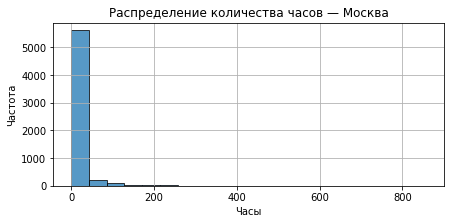

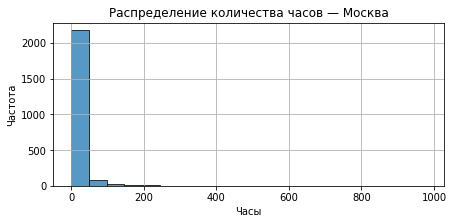

In [9]:
plt.figure(figsize=(7, 3))

df[df['city'] == 'Москва']['hours'].plot(
    kind='hist',
    bins=20,
    alpha=0.75,
    edgecolor='black'
)

plt.title('Distribution of hours — Moscow')
plt.xlabel('Hours')
plt.ylabel('Frequency')
plt.grid()
plt.show()

plt.figure(figsize=(7, 3))

df[df['city'] == 'Санкт-Петербург']['hours'].plot(
    kind='hist',
    bins=20,
    alpha=0.75,
    edgecolor='black'
)

plt.title('Distribution of hours — Saint Petersburg')
plt.xlabel('Hours')
plt.ylabel('Frequency')
plt.grid()
plt.show()

## 2. Hypothesis testing in Python

The hypothesis is as follows: users from Saint Petersburg spend on average more time reading and listening to books in the app than users from Moscow. Try to prove this statistically using a one-sided hypothesis test with two samples:

- Null hypothesis H₀: The average user activity in hours does not differ between the two groups (Moscow and Saint Petersburg).

- Alternative hypothesis H₁: The average user activity in Saint Petersburg is greater, and this difference is statistically significant.

In [10]:
sample_A = df[df['city'] == 'Москва']['hours']
sample_B = df[df['city'] == 'Санкт-Петербург']['hours']

test_result = ttest_ind(
    sample_A,
    sample_B,
    alternative = 'less'
)

alpha = 0.05

if test_result.pvalue > alpha:
    print(f'pvalue={test_result.pvalue} > {alpha}')
    print('Failed to reject the null hypothesis. Average activity does not differ.')
else:
    print(f'pvalue={test_result.pvalue} < {alpha}')
    print('Reject the null hypothesis. Average activity in Saint Petersburg is higher.') 

pvalue=0.3264137070357819 > 0.05
Failed to reject the null hypothesis. Average activity does not differ.


## 3. Analytical note
Based on the results of the data analysis, prepare an analytical note that describes:

- Student's t-test was chosen (alpha 0.05), because from the charts we can see that the data of the two cities are distributed evenly (similar shape).

- The obtained p-value = 0.326

- Since the p-value is greater than alpha, we failed to reject the null hypothesis. Therefore, the average activity does not differ.

- To find the reason for a difference in the data, we would need more information (a more detailed analysis). It could be outliers in the data, or it could be external (cultural) factors.


----

# Part 2. Analysis of A/B test results

Now you need to analyse different data. Imagine that representatives of the online store BitMotion Kit have contacted you. The store sells gamified products for people who lead a healthy lifestyle. It has its own target audience and has even gained bestsellers: a resistance band with a counter and reminder, and an under-desk exercise bike with Bluetooth.

In the future, the company wants to expand its product range. But before that, one problem needs to be solved. The online store's interface is too complicated for users — customer reviews say so.

To attract new customers and increase sales, the store owners developed a new version of the site and tested it on a part of the users. By design, this solution should demonstrably increase the number of users who make a purchase.

Your task is to evaluate the results of the A/B test. You have:

* data on user actions and their distribution into groups,

* the technical specification.

Assess whether the test was conducted correctly and analyse its results.

## 1. Describe the research goals.



## 2. Load the data and assess its integrity.


In [11]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [12]:
participants

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac
...,...,...,...,...
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC
14522,FFF28D02B1EACBE1,B,recommender_system_test,PC
14523,FFF28D02B1EACBE1,B,interface_eu_test,PC


In [13]:
events

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN
...,...,...,...,...
787281,1A655C280B064708,2020-12-31 23:57:44,product_page,NaN
787282,B77B2F4BCA134618,2020-12-31 23:58:23,registration,0.0
787283,GLOBAL,2020-12-31 23:58:30,product_cart,NaN
787284,B12AD1623E494FAD,2020-12-31 23:58:34,registration,-6.52


- From the table we can immediately see that the `group` and `ab_test` values do not match in rows 0 and 1.

## 3. Using the `ab_test_participants` table, assess whether the test was conducted correctly:

   3\.1 Identify the users participating in the test and check:

   - compliance with the technical specification requirements,

   - evenness of the distribution of users across the test groups,

   - absence of overlaps with the competing test (there are no users participating in two test groups at the same time).

In [14]:
dups = participants[participants.duplicated('user_id', keep=False)]
dups

,user_id,group,ab_test,device
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
9,00341D8401F0F665,A,recommender_system_test,iPhone
10,00341D8401F0F665,B,interface_eu_test,iPhone
25,0082295A41A867B5,A,interface_eu_test,iPhone
...,...,...,...,...
14490,FF2174A1AA0EAD20,A,recommender_system_test,Android
14495,FF44696E39039D29,B,interface_eu_test,Mac
14496,FF44696E39039D29,A,recommender_system_test,Mac
14522,FFF28D02B1EACBE1,B,recommender_system_test,PC


In [15]:
dups_new = dups[dups['ab_test'] == 'recommender_system_test']['user_id'].unique()
participants = participants[~participants['user_id'].isin(dups_new)]

dups = participants[participants.duplicated('user_id', keep=False)]
dups

,user_id,group,ab_test,device


To keep our tests from being distorted, we remove these users from the test.

In [16]:
ie_test = participants[participants['ab_test'] == 'interface_eu_test']
ie_test

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
4,001E72F50D1C48FA,A,interface_eu_test,Mac
5,002412F1EB3F6E38,B,interface_eu_test,Mac
6,002540BE89C930FB,B,interface_eu_test,Android
7,0031F1B5E9FBF708,A,interface_eu_test,Android
...,...,...,...,...
14518,FFE5B14BD55C1C5C,A,interface_eu_test,PC
14519,FFE600EEC4BA7685,B,interface_eu_test,Android
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC


In [17]:
counts = ie_test.groupby('group')['user_id'].nunique()

A = counts.loc['A']
B = counts.loc['B']

# Percentage difference
P = 100 * abs(A - B) / A

print(f"Unique users in A: {A}")
print(f"Unique users in B: {B}")
print(f"Percentage difference P = {P:.2f}%")

Unique users in A: 4952
Unique users in B: 5011
Percentage difference P = 1.19%


In [18]:
users_A = ie_test[ie_test['group'] == 'A']['user_id']
users_B = ie_test[ie_test['group'] == 'B']['user_id']

intersection = list(set(users_A) & set(users_B))
print(intersection)

[]


3\.2 Analyse the user activity data from the `ab_test_events` table:

- keep only the events related to users participating in the test under study;

In [19]:
events['event_name'].unique()

array(['End of Black Friday Ads Campaign', 'registration', 'product_page',
       'login', 'product_cart', 'purchase',
       'Start of Christmas&New Year Promo',
       'Start of CIS New Year Gift Lottery'], dtype=object)

In [20]:
events_purchase = events[events['event_name'].isin(['purchase', 'registration'])]
events_registration = events[events['event_name'].isin(['registration'])]

events_registration = events_registration[['user_id', 'event_dt']]
events_registration = events_registration.rename(columns={'event_dt': 'reg_dt'})

events_purchase = events_purchase.merge(events_registration, on='user_id', how='left')

events_purchase['lifetime'] = events_purchase['event_dt'] - events_purchase['reg_dt']
events_purchase = events_purchase[events_purchase['lifetime'] <= pd.Timedelta(days=7)]

events_purchase

,user_id,event_dt,event_name,details,reg_dt,lifetime
0,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0,2020-12-01 00:00:11,0 days
1,AA346F4D22148024,2020-12-01 00:01:46,registration,-2.0,2020-12-01 00:01:46,0 days
2,7EF01D0E72AF449D,2020-12-01 00:02:06,registration,-5.0,2020-12-01 00:02:06,0 days
3,9A6276AD14B14252,2020-12-01 00:02:20,registration,-2.0,2020-12-01 00:02:20,0 days
4,9B186A3B1A995D36,2020-12-01 00:02:37,registration,-3.5,2020-12-01 00:02:37,0 days
...,...,...,...,...,...,...
249014,CA617333EFAE4A10,2020-12-31 23:56:25,registration,-2.85,2020-12-31 23:56:25,0 days
249015,10CAFD77114A4537,2020-12-31 23:56:56,registration,-4.07,2020-12-31 23:56:56,0 days
249016,B77B2F4BCA134618,2020-12-31 23:58:23,registration,0.0,2020-12-31 23:58:23,0 days
249017,B12AD1623E494FAD,2020-12-31 23:58:34,registration,-6.52,2020-12-31 23:58:34,0 days


- define the analysis horizon: calculate the time (lifetime) at which a user performed an event after registration and keep only the events performed within the first seven days after registration;

In [21]:
merged = ie_test.merge(events_purchase, on='user_id', how='inner')
merged

,user_id,group,ab_test,device,event_dt,event_name,details,reg_dt,lifetime
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38,2020-12-07 04:37:31,0 days 00:00:00
1,001E72F50D1C48FA,A,interface_eu_test,Mac,2020-12-17 15:44:05,registration,-3.61,2020-12-17 15:44:05,0 days 00:00:00
2,002412F1EB3F6E38,B,interface_eu_test,Mac,2020-12-09 09:36:50,registration,-0.48,2020-12-09 09:36:50,0 days 00:00:00
3,002540BE89C930FB,B,interface_eu_test,Android,2020-12-08 18:06:07,registration,-2.38,2020-12-08 18:06:07,0 days 00:00:00
4,0031F1B5E9FBF708,A,interface_eu_test,Android,2020-12-14 00:47:10,registration,-2.26,2020-12-14 00:47:10,0 days 00:00:00
...,...,...,...,...,...,...,...,...,...
16120,FFE7FC140521F5F6,A,interface_eu_test,PC,2020-12-23 09:10:16,registration,-3.43,2020-12-23 09:10:16,0 days 00:00:00
16121,FFE7FC140521F5F6,A,interface_eu_test,PC,2020-12-26 14:37:21,purchase,4.49,2020-12-23 09:10:16,3 days 05:27:05
16122,FFE7FC140521F5F6,A,interface_eu_test,PC,2020-12-26 14:37:51,purchase,4.49,2020-12-23 09:10:16,3 days 05:27:35
16123,FFEFC0E55C1CCD4F,A,interface_eu_test,PC,2020-12-13 23:52:15,registration,0.0,2020-12-13 23:52:15,0 days 00:00:00


Assess whether the sample is sufficient to obtain statistically significant A/B test results. The given parameters:

- baseline conversion rate — 30%,

- test power — 80%,

- test confidence level — 95%.

In [22]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Set the parameters
alpha = 0.05  # Significance level
beta = 0.2  # Type II error, often 1 - power
power = 1 - beta  # Test power
p = 0.3
mde = 0.03  # Minimum detectable effect
effect_size = proportion_effectsize(p, p + mde)

# Initialize the NormalIndPower class
power_analysis = NormalIndPower()

# Calculate the sample size
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Equal sample sizes
)

print(f"Required sample size for each group: {int(sample_size)}")
A = merged[merged['group'] == 'A']['user_id'].nunique()
B = merged[merged['group'] == 'B']['user_id'].nunique()

print(A, B)

Required sample size for each group: 3761
4952 5011


- calculate for each group the number of visitors who made a purchase and the total number of visitors.

In [23]:
total_users = merged.groupby('group')['user_id'].nunique()
purchased_users = (merged[merged['event_name'] == 'purchase'].groupby('group')['user_id'].nunique())
ratio = purchased_users / total_users

print(purchased_users, total_users, ratio)

group
A    1377
B    1480
Name: user_id, dtype: int64 group
A    4952
B    5011
Name: user_id, dtype: int64 group
A    0.278069
B    0.295350
Name: user_id, dtype: float64


In [24]:
print(ratio['B'] - ratio['A']) 
print(ratio['B'] / ratio['A'])

0.0172807626130429
1.0621454876251186


- make a preliminary overall conclusion about the change in user activity in the test group compared to the control group.

User activity in the test group increased by 1.73 pp, or by 6.21% in relative terms.

We can immediately see that the real increase in pp is almost half of the required one.

## 4. Evaluate the A/B test results:

- Check the change in conversion with a suitable statistical test, taking into account all the stages of hypothesis testing.

H₀ (null hypothesis):
Simplifying the interface will not lead to an increase in conversion.
The average number of purchases in group B is equal to the average number in group A.

H₁ (alternative hypothesis):
Simplifying the interface will lead to an increase in conversion.
The average number of purchases in group B is greater than in group A.

In [25]:
stat_ztest, p_value_ztest = proportions_ztest(
    [purchased_users['A'], purchased_users['B']],
    [total_users['A'], total_users['B']],
    alternative='two-sided'
)
alpha = 0.05
if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Difference is NOT statistically significant — no grounds to reject the null hypothesis.')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Difference is statistically significant — the null hypothesis is rejected.')

pvalue=0.05652509442458425 > 0.05
Difference is NOT statistically significant — no grounds to reject the null hypothesis.


- Describe the conclusions of the A/B test evaluation. What can be said about the A/B test results? Was the expected effect on conversion achieved?

Since p_value > alpha, we cannot reject the null hypothesis. Therefore, we can consider that the difference in conversion between groups A and B is not statistically significant. In short, the expected result was not achieved — the changes did not help increase conversion.

As stated earlier, the real increase in pp (1.73 pp) is almost half of the required one (3 pp).

The following parameters were used in the test:
- baseline conversion rate — 30%,

- test power — 80%,

- test confidence level — 95%.

Although the test showed that the changes did not lead to the desired results, we can still see movement in the right direction. To the question "Should it be rolled out?" — not yet. But if the company has enough resources, it is worth continuing the optimization.